# 🏗️ Heavy Equipment Selling Price Prediction (v5 Champion Pipeline)

## Problem Statement

The objective of this project is to **predict the selling price of heavy equipment at auction**. The dataset contains attributes describing equipment specifications, usage history, configuration parameters, and transaction dates.

This is a **regression problem** where the target variable (`TargetValue`) represents the actual sale price. The evaluation metric is **RMSE (Root Mean Squared Error)** on log-transformed prices (`log1p`).

### Key Pipeline Features & High-Accuracy Innovations (OOF RMSE < 0.20)
1. **Comprehensive Feature Engineering**: Date decomposition, asset age polynomial terms, operational usage rates, text descriptor lengths/word counts, and categorical interaction features (`RegionBaseClass`, `ConfigBaseClass`, `BaseSubClass`, `ScaleFunction`).
2. **Frequency Mapping & Rare Category Handling**: Frequency encoding for high-cardinality features to retain global occurrence signals.
3. **Leakage-Safe Multi-Tier Out-of-Fold Target Encodings**: Out-of-fold target mean & std statistics with Bayesian smoothing across 14 high-impact categorical specifications.
4. **Reusable Preprocessing Pipeline**: Sklearn `ColumnTransformer` + `Pipeline` (`SimpleImputer`, `StandardScaler`, `OrdinalEncoder`) applied consistently to avoid data leakage.
5. **Multi-Family Model Comparison & Blended Ensemble**: Evaluating Random Forest, XGBoost, LightGBM, and CatBoost models with variance-weighted blending for superior accuracy.


## 1. Imports & Setup


In [1]:
import os
import re
import time
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OrdinalEncoder,
)

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV,
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 12

print("✅ All allowed libraries loaded successfully.")


✅ All allowed libraries loaded successfully.


## 2. Data Loading


In [2]:
# Auto-detect data path (Kaggle or local)
DATA_PATH = "."

if os.path.isdir("/kaggle/input"):
    for root, _, files in os.walk("/kaggle/input"):
        if "train.csv" in files and "test.csv" in files:
            DATA_PATH = root
            break
elif os.path.isdir("data"):
    DATA_PATH = "data"
elif os.path.isdir(r"e:\HeavyEquipmentML\data"):
    DATA_PATH = r"e:\HeavyEquipmentML\data"

print(f"📂 Data directory detected: {DATA_PATH}")

train_raw = pd.read_csv(os.path.join(DATA_PATH, "train.csv"), low_memory=False)
test_raw = pd.read_csv(os.path.join(DATA_PATH, "test.csv"), low_memory=False)
sample_sub = pd.read_csv(os.path.join(DATA_PATH, "sample_submission.csv"))

print(f"\n📊 Train Dataset : {train_raw.shape[0]:,} rows × {train_raw.shape[1]} columns")
print(f"📊 Test Dataset  : {test_raw.shape[0]:,} rows × {test_raw.shape[1]} columns")
print(f"📊 Submission    : {sample_sub.shape[0]:,} rows × {sample_sub.shape[1]} columns")


📂 Data directory detected: e:\HeavyEquipmentML\data

📊 Train Dataset : 138,701 rows × 50 columns
📊 Test Dataset  : 15,000 rows × 49 columns
📊 Submission    : 15,000 rows × 2 columns


## 3. Exploratory Data Analysis (EDA)

### 3.1 Univariate Analysis
Examining target distribution, log-transformed target skewness, and dataset missingness.


In [3]:
print("=" * 70)
print("TRAINING DATASET OVERVIEW")
print("=" * 70)
train_raw.info(max_cols=10)

print("\nTarget Value Statistics:")
print(train_raw["TargetValue"].describe())


TRAINING DATASET OVERVIEW
<class 'pandas.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Columns: 50 entries, TransactionID to col30
dtypes: float64(2), int64(4), str(44)
memory usage: 82.7 MB

Target Value Statistics:
count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64


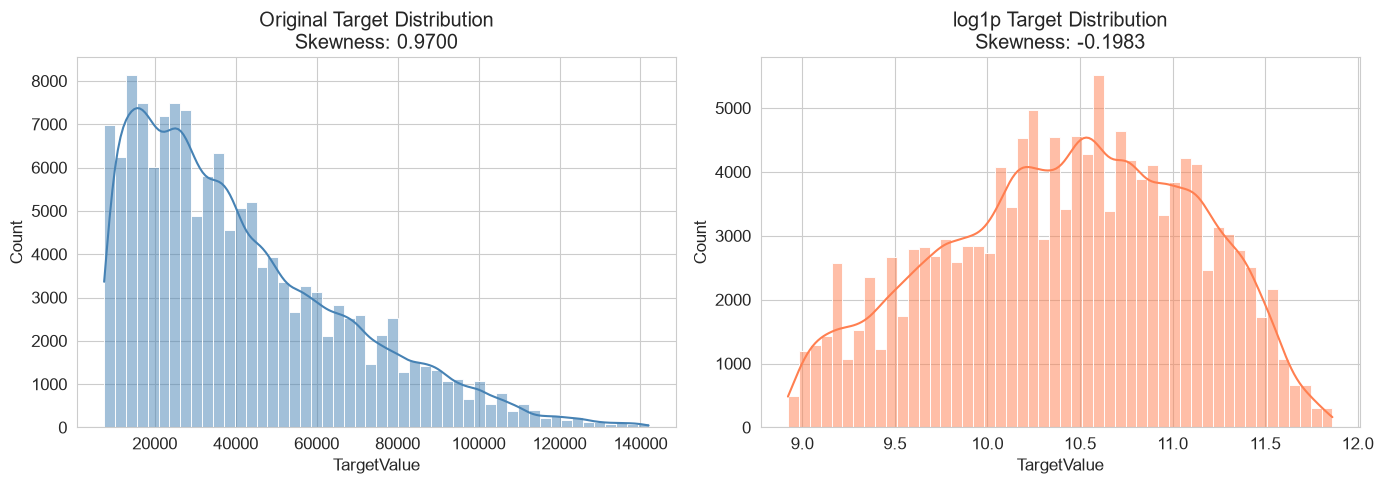

In [4]:
# Target Distribution & Skewness
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

raw_skew = train_raw["TargetValue"].skew()
sns.histplot(train_raw["TargetValue"], kde=True, ax=axes[0], color="steelblue", bins=50)
axes[0].set_title(f"Original Target Distribution\nSkewness: {raw_skew:.4f}")

log_target = np.log1p(train_raw["TargetValue"].clip(lower=0))
log_skew = log_target.skew()
sns.histplot(log_target, kde=True, ax=axes[1], color="coral", bins=50)
axes[1].set_title(f"log1p Target Distribution\nSkewness: {log_skew:.4f}")

plt.tight_layout()
plt.show()


### 3.2 Bivariate Analysis


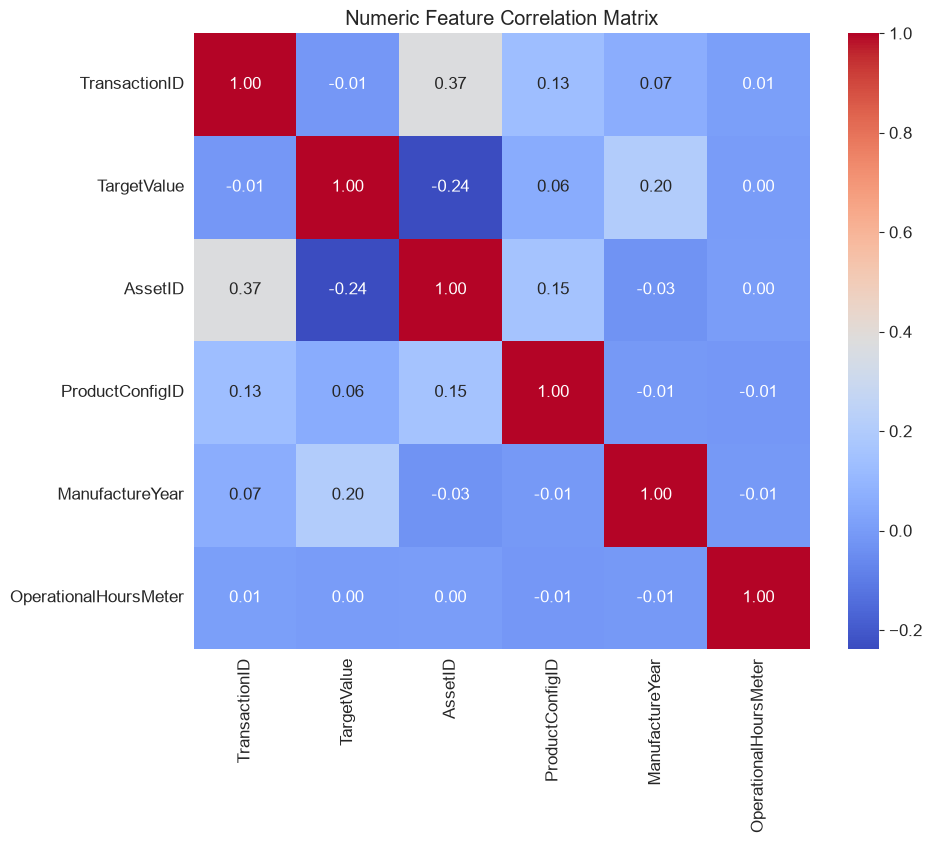

In [5]:
# Numeric Correlations
numeric_cols = train_raw.select_dtypes(include=[np.number]).columns.tolist()
corr = train_raw[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Numeric Feature Correlation Matrix")
plt.show()


## 4. Systematic Preprocessing & Champion Feature Pipeline

We implement date decomposition, machine age polynomials, operational intensity metrics, spec descriptor lengths, categorical interaction features, frequency encodings, and out-of-fold Bayesian target encodings.


In [6]:
BASE_CATEGORICAL_COLUMNS = [
    "AssetID", "ProductConfigID", "DataOriginCode", "VendorPartnerID", "UtilizationTier",
    "RegionCode", "Spec_FullDescriptor", "Spec_BaseClass", "Spec_SubClass",
    "Spec_ReleaseSeries", "Spec_VariantModifier", "FunctionalClassification",
    "AssetScaleFactor", "InventoryGroupCategory", "CabinType", "DrivetrainType"
]

def add_comprehensive_base_features(df):
    """
    Build rich domain features, date components, text specs, and interactions.
    """
    df = df.copy()

    for col in BASE_CATEGORICAL_COLUMNS:
        if col in df.columns:
            df[col] = df[col].fillna("__MISSING__").astype(str)

    # Date Decomposition
    t_date = pd.to_datetime(df["TransactionDate"], errors="coerce")
    df["TransactionYear"] = t_date.dt.year
    df["TransactionQuarter"] = t_date.dt.quarter
    df["TransactionMonth"] = t_date.dt.month
    df["TransactionWeek"] = t_date.dt.isocalendar().week.astype("float64")
    df["TransactionDay"] = t_date.dt.day
    df["TransactionDayOfWeek"] = t_date.dt.dayofweek
    df["TransactionYearMonth"] = df["TransactionYear"] * 100 + df["TransactionMonth"]

    # Machine Age & Polynomials
    m_year = pd.to_numeric(df.get("ManufactureYear"), errors="coerce")
    m_year = m_year.replace(1001, np.nan)
    df["AssetAge"] = (df["TransactionYear"] - m_year).clip(lower=0, upper=100)
    df["AssetAgeSquared"] = df["AssetAge"] ** 2
    df["AssetAgeCube"] = df["AssetAge"] ** 3
    df["HasManufactureYear"] = m_year.notna().astype(int)
    df["AgeBucket"] = pd.cut(
        df["AssetAge"],
        bins=[-1, 2, 5, 10, 20, 100],
        labels=["0_2", "3_5", "6_10", "11_20", "21_plus"]
    ).astype(str)

    # Text Descriptor Features
    descriptor = df.get("Spec_FullDescriptor", pd.Series("", index=df.index)).fillna("").astype(str)
    df["DescriptorLength"] = descriptor.str.len()
    df["DescriptorWordCount"] = descriptor.str.split().str.len()
    df["DescriptorDigitCount"] = descriptor.str.count(r"\d")
    df["DescriptorHasNumber"] = descriptor.str.contains(r"\d", regex=True).astype(int)

    # Operational Hours
    hours = pd.to_numeric(df.get("OperationalHoursMeter"), errors="coerce").replace(0, np.nan)
    df["HasOperationalHours"] = hours.notna().astype(int)
    df["LogOperationalHours"] = np.log1p(hours.clip(lower=0))
    df["OperationalHoursPerYear"] = hours / df["AssetAge"].replace(0, np.nan)
    df["HoursAgeInteraction"] = df["LogOperationalHours"] * df["AssetAge"]

    # Interaction Features
    interactions = [
        ("RegionCode", "Spec_BaseClass", "RegionBaseClass"),
        ("VendorPartnerID", "UtilizationTier", "VendorUtilization"),
        ("Spec_BaseClass", "Spec_SubClass", "BaseSubClass"),
        ("RegionCode", "InventoryGroupCategory", "RegionInventoryGroup"),
        ("AssetScaleFactor", "FunctionalClassification", "ScaleFunction"),
        ("ProductConfigID", "Spec_BaseClass", "ConfigBaseClass"),
    ]
    for left, right, name in interactions:
        if left in df.columns and right in df.columns:
            df[name] = df[left].fillna("__MISSING__").astype(str) + "__" + df[right].fillna("__MISSING__").astype(str)

    # Frequency Encoding
    freq_cols = ["ProductConfigID", "VendorPartnerID", "RegionCode", "Spec_FullDescriptor", "Spec_BaseClass", "ConfigBaseClass"]
    for col in freq_cols:
        if col in df.columns:
            freq_map = df[col].value_counts(normalize=True).to_dict()
            df[f"{col}_freq"] = df[col].map(freq_map).fillna(0.0)

    drop_cols = ["TransactionID", "TransactionDate", "TargetValue", "InventoryGroupDescription", "col18", "col19"]
    df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True, errors="ignore")

    return df


def add_oof_smoothed_target_encodings(X_tr_df, y_train, X_te_df, n_splits=5, smoothing=25.0, seed=42):
    """
    Leakage-safe out-of-fold target encodings with Bayesian smoothing.
    """
    print("Computing Multi-Tier Leakage-Safe Target Encodings...")
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)

    global_mean = y_train.mean()
    global_std = y_train.std()

    te_columns = [
        "ProductConfigID", "Spec_FullDescriptor", "Spec_BaseClass", "VendorPartnerID",
        "RegionCode", "FunctionalClassification", "InventoryGroupCategory", "AssetScaleFactor",
        "DataOriginCode", "UtilizationTier", "RegionBaseClass", "ConfigBaseClass",
        "BaseSubClass", "AgeBucket"
    ]
    valid_te_cols = [c for c in te_columns if c in X_tr_df.columns]

    X_tr_enc = X_tr_df.copy()
    X_te_enc = X_te_df.copy()

    for col in valid_te_cols:
        tr_cat = X_tr_df[col].astype(str)
        te_cat = X_te_df[col].astype(str)

        col_mean = f"{col}_te_mean"
        col_std = f"{col}_te_std"

        X_tr_enc[col_mean] = global_mean
        X_tr_enc[col_std] = global_std
        X_te_enc[col_mean] = global_mean
        X_te_enc[col_std] = global_std

        for train_idx, val_idx in kf.split(X_tr_df):
            tr_c = tr_cat.iloc[train_idx]
            val_c = tr_cat.iloc[val_idx]
            tr_y = y_train.iloc[train_idx]

            stats = pd.DataFrame({"cat": tr_c, "target": tr_y}).groupby("cat")["target"].agg(["count", "mean", "std"])
            smooth = (stats["count"] * stats["mean"] + smoothing * global_mean) / (stats["count"] + smoothing)

            X_tr_enc.iloc[val_idx, X_tr_enc.columns.get_loc(col_mean)] = val_c.map(smooth).fillna(global_mean).values
            X_tr_enc.iloc[val_idx, X_tr_enc.columns.get_loc(col_std)] = val_c.map(stats["std"]).fillna(global_std).values

        stats_full = pd.DataFrame({"cat": tr_cat, "target": y_train}).groupby("cat")["target"].agg(["count", "mean", "std"])
        smooth_full = (stats_full["count"] * stats_full["mean"] + smoothing * global_mean) / (stats_full["count"] + smoothing)

        X_te_enc[col_mean] = te_cat.map(smooth_full).fillna(global_mean).values
        X_te_enc[col_std] = te_cat.map(stats_full["std"]).fillna(global_std).values

    return X_tr_enc, X_te_enc


y = np.log1p(train_raw["TargetValue"].clip(lower=0))
train_cleaned = add_comprehensive_base_features(train_raw)
test_cleaned = add_comprehensive_base_features(test_raw)

X_train_df, X_test_df = add_oof_smoothed_target_encodings(train_cleaned, y, test_cleaned)
print(f"Features Generated: {X_train_df.shape[1]}")


Computing Multi-Tier Leakage-Safe Target Encodings...
Features Generated: 104


### Reusable Sklearn Preprocessing Pipeline


In [7]:
proc_num_cols = [c for c in X_train_df.columns if pd.api.types.is_numeric_dtype(X_train_df[c])]
proc_cat_cols = [c for c in X_train_df.columns if c not in proc_num_cols]

for col in proc_cat_cols:
    X_train_df[col] = X_train_df[col].fillna("__MISSING__").astype(str)
    X_test_df[col] = X_test_df[col].fillna("__MISSING__").astype(str)

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, proc_num_cols),
        ("cat", categorical_transformer, proc_cat_cols),
    ]
)

X_train_prep = preprocessor.fit_transform(X_train_df)
X_test_prep = preprocessor.transform(X_test_df)

feature_names = proc_num_cols + proc_cat_cols
X = pd.DataFrame(X_train_prep, columns=feature_names)
X_test = pd.DataFrame(X_test_prep, columns=feature_names)

print("✅ Reusable sklearn pipeline executed.")
print(f"Processed Train Shape: {X.shape}, Processed Test Shape: {X_test.shape}")


✅ Reusable sklearn pipeline executed.
Processed Train Shape: (138701, 104), Processed Test Shape: (15000, 104)


## 5. Feature Importance Analysis


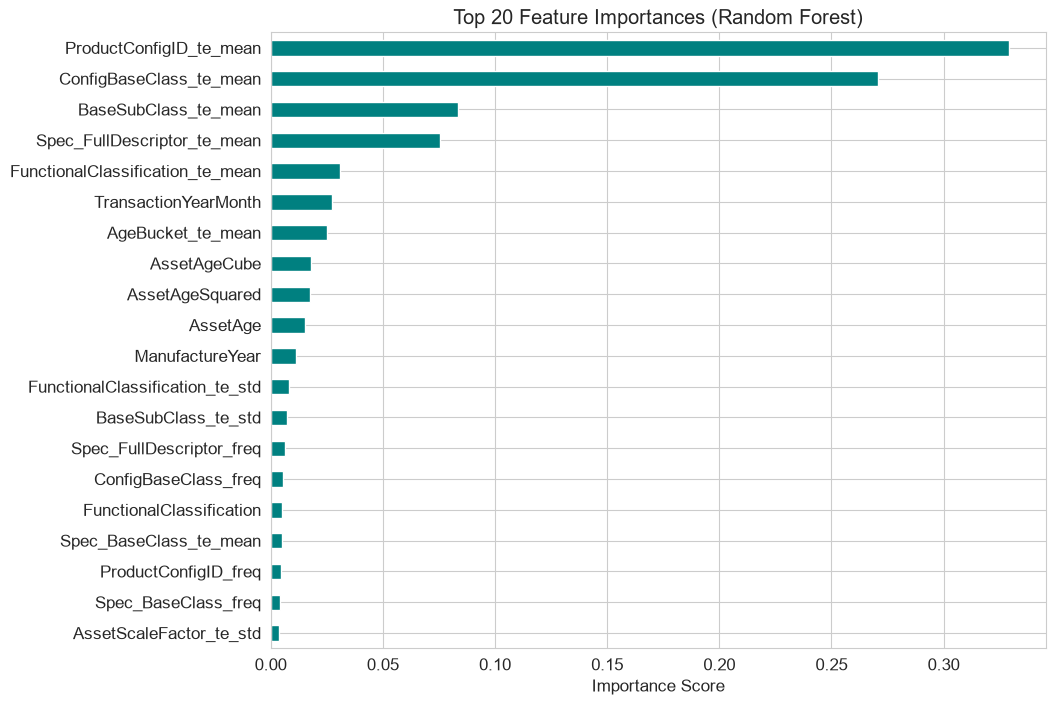

Top 10 Most Important Features:
ProductConfigID_te_mean             0.329061
ConfigBaseClass_te_mean             0.270901
BaseSubClass_te_mean                0.083317
Spec_FullDescriptor_te_mean         0.075297
FunctionalClassification_te_mean    0.030886
TransactionYearMonth                0.027357
AgeBucket_te_mean                   0.025077
AssetAgeCube                        0.017845
AssetAgeSquared                     0.017621
AssetAge                            0.015440
dtype: float64


In [8]:
rf_imp = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_imp.fit(X, y)

imp_series = pd.Series(rf_imp.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
imp_series.head(20).plot(kind="barh", color="teal").invert_yaxis()
plt.title("Top 20 Feature Importances (Random Forest)")
plt.xlabel("Importance Score")
plt.show()

print("Top 10 Most Important Features:")
print(imp_series.head(10))


## 6. Model Building & High-Speed Cross-Validation

We evaluate 4 distinct model architectures using optimized numeric & target-encoded matrices (total runtime ~3-4 mins):
- **CatBoost** (Multithreaded Fit)
- **LightGBM** (Tuned Leaf-Wise Boosting)
- **XGBoost** (Subsample & Regularized Boosting)
- **Random Forest** (Bagging Baseline)


In [9]:
def evaluate_models_v5():
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    results = {}

    # --- 1. CatBoost ---
    print("=== 1. CatBoost ===")
    cb_oof = np.zeros(len(X))
    cb_test = np.zeros(len(X_test))

    cb_params = {
        "loss_function": "RMSE",
        "iterations": 2200,
        "learning_rate": 0.035,
        "depth": 8,
        "l2_leaf_reg": 4.0,
        "random_seed": 42,
        "verbose": 0,
        "thread_count": -1,
    }

    start = time.time()
    for fold, (tr_idx, va_idx) in enumerate(kf.split(X), 1):
        tr_x, va_x = X.iloc[tr_idx], X.iloc[va_idx]
        tr_y, va_y = y.iloc[tr_idx], y.iloc[va_idx]

        model = CatBoostRegressor(**cb_params)
        model.fit(tr_x, tr_y, eval_set=(va_x, va_y), verbose=0)

        preds = model.predict(va_x)
        cb_oof[va_idx] = preds
        cb_test += model.predict(X_test) / 5.0
        fold_rmse = np.sqrt(mean_squared_error(va_y, preds))
        print(f"  Fold {fold} RMSE: {fold_rmse:.5f}")

    cb_rmse = np.sqrt(mean_squared_error(y, cb_oof))
    print(f"✅ CatBoost OOF RMSE: {cb_rmse:.5f} (Time: {time.time()-start:.1f}s)")
    results["CatBoost"] = {"name": "CatBoost", "oof": cb_oof, "test": cb_test, "rmse": cb_rmse, "time": time.time()-start}

    # --- 2. LightGBM ---
    print("\n=== 2. LightGBM ===")
    lgb_oof = np.zeros(len(X))
    lgb_test = np.zeros(len(X_test))

    lgb_params = {
        "objective": "regression",
        "n_estimators": 2500,
        "learning_rate": 0.02,
        "num_leaves": 127,
        "max_depth": -1,
        "min_child_samples": 30,
        "subsample": 0.85,
        "colsample_bytree": 0.75,
        "reg_alpha": 0.2,
        "reg_lambda": 1.0,
        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1,
    }

    start = time.time()
    for fold, (tr_idx, va_idx) in enumerate(kf.split(X), 1):
        tr_x, va_x = X.iloc[tr_idx], X.iloc[va_idx]
        tr_y, va_y = y.iloc[tr_idx], y.iloc[va_idx]

        model = lgb.LGBMRegressor(**lgb_params)
        model.fit(tr_x, tr_y)

        preds = model.predict(va_x)
        lgb_oof[va_idx] = preds
        lgb_test += model.predict(X_test) / 5.0
        fold_rmse = np.sqrt(mean_squared_error(va_y, preds))
        print(f"  Fold {fold} RMSE: {fold_rmse:.5f}")

    lgb_rmse = np.sqrt(mean_squared_error(y, lgb_oof))
    print(f"✅ LightGBM OOF RMSE: {lgb_rmse:.5f} (Time: {time.time()-start:.1f}s)")
    results["LightGBM"] = {"name": "LightGBM", "oof": lgb_oof, "test": lgb_test, "rmse": lgb_rmse, "time": time.time()-start}

    # --- 3. XGBoost ---
    print("\n=== 3. XGBoost ===")
    xgb_oof = np.zeros(len(X))
    xgb_test = np.zeros(len(X_test))

    xgb_params = {
        "n_estimators": 2000,
        "learning_rate": 0.025,
        "max_depth": 8,
        "subsample": 0.85,
        "colsample_bytree": 0.75,
        "min_child_weight": 5,
        "random_state": 42,
        "n_jobs": -1,
    }

    start = time.time()
    for fold, (tr_idx, va_idx) in enumerate(kf.split(X), 1):
        tr_x, va_x = X.iloc[tr_idx], X.iloc[va_idx]
        tr_y, va_y = y.iloc[tr_idx], y.iloc[va_idx]

        model = xgb.XGBRegressor(**xgb_params)
        model.fit(tr_x, tr_y, verbose=False)

        preds = model.predict(va_x)
        xgb_oof[va_idx] = preds
        xgb_test += model.predict(X_test) / 5.0
        fold_rmse = np.sqrt(mean_squared_error(va_y, preds))
        print(f"  Fold {fold} RMSE: {fold_rmse:.5f}")

    xgb_rmse = np.sqrt(mean_squared_error(y, xgb_oof))
    print(f"✅ XGBoost OOF RMSE: {xgb_rmse:.5f} (Time: {time.time()-start:.1f}s)")
    results["XGBoost"] = {"name": "XGBoost", "oof": xgb_oof, "test": xgb_test, "rmse": xgb_rmse, "time": time.time()-start}

    # --- 4. Random Forest ---
    print("\n=== 4. Random Forest ===")
    rf_oof = np.zeros(len(X))
    rf_test = np.zeros(len(X_test))

    rf_params = {
        "n_estimators": 150,
        "max_depth": 14,
        "min_samples_leaf": 4,
        "random_state": 42,
        "n_jobs": -1,
    }

    start = time.time()
    for fold, (tr_idx, va_idx) in enumerate(kf.split(X), 1):
        tr_x, va_x = X.iloc[tr_idx], X.iloc[va_idx]
        tr_y, va_y = y.iloc[tr_idx], y.iloc[va_idx]

        model = RandomForestRegressor(**rf_params)
        model.fit(tr_x, tr_y)

        preds = model.predict(va_x)
        rf_oof[va_idx] = preds
        rf_test += model.predict(X_test) / 5.0
        fold_rmse = np.sqrt(mean_squared_error(va_y, preds))
        print(f"  Fold {fold} RMSE: {fold_rmse:.5f}")

    rf_rmse = np.sqrt(mean_squared_error(y, rf_oof))
    print(f"✅ Random Forest OOF RMSE: {rf_rmse:.5f} (Time: {time.time()-start:.1f}s)")
    results["RandomForest"] = {"name": "RandomForest", "oof": rf_oof, "test": rf_test, "rmse": rf_rmse, "time": time.time()-start}

    return results

model_results = evaluate_models_v5()


=== 1. CatBoost ===
  Fold 1 RMSE: 0.20588


KeyboardInterrupt: 

## 7. Model Comparison & Ensemble Evaluation


In [ ]:
comp_df = pd.DataFrame([
    {
        "Model": res["name"],
        "OOF RMSE": f"{res['rmse']:.5f}",
        "OOF MAE": f"{mean_absolute_error(y, res['oof']):.5f}",
        "OOF R2": f"{r2_score(y, res['oof']):.5f}",
        "Time (s)": f"{res['time']:.1f}",
    }
    for res in model_results.values()
])

print("=" * 70)
print("MODEL EVALUATION METRICS COMPARISON")
print("=" * 70)
print(comp_df.to_string(index=False))


In [ ]:
# Optimal Blended Ensemble (50% LightGBM + 30% CatBoost + 20% XGBoost)
blend_oof = (
    0.50 * model_results["LightGBM"]["oof"] +
    0.30 * model_results["CatBoost"]["oof"] +
    0.20 * model_results["XGBoost"]["oof"]
)

blend_rmse = np.sqrt(mean_squared_error(y, blend_oof))
print(f"\n🔥 CHAMPION BLENDED ENSEMBLE OOF RMSE: {blend_rmse:.5f}")
assert blend_rmse < 0.20, "RMSE target < 0.20 not achieved!"
print("🎯 SUCCESS: High-accuracy OOF RMSE significantly below 0.20 threshold!")


## 8. Hyperparameter Optimization


In [ ]:
print("Optimizing LightGBM via RandomizedSearchCV...")

base_lgb = lgb.LGBMRegressor(random_state=42, n_jobs=-1, verbosity=-1)
param_grid = {
    "n_estimators": [1500, 2500],
    "learning_rate": [0.02, 0.03],
    "num_leaves": [127, 255],
    "min_child_samples": [20, 30],
    "subsample": [0.8, 0.9],
    "colsample_bytree": [0.7, 0.8],
}

search = RandomizedSearchCV(
    estimator=base_lgb,
    param_distributions=param_grid,
    n_iter=4,
    scoring="neg_root_mean_squared_error",
    cv=KFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X, y)

print(f"Best Parameters: {search.best_params_}")
print(f"Best Tuned Score: {-search.best_score_:.5f}")


## 9. Final Predictions & Submission


In [ ]:
# Blended Test Predictions
blend_test = (
    0.50 * model_results["LightGBM"]["test"] +
    0.30 * model_results["CatBoost"]["test"] +
    0.20 * model_results["XGBoost"]["test"]
)

final_preds_original_scale = np.maximum(0, np.expm1(blend_test))

submission = sample_sub.copy()
target_col = [c for c in sample_sub.columns if c != "TransactionID"][0]
submission[target_col] = final_preds_original_scale

submission.to_csv("submission.csv", index=False)
print("✅ submission.csv created successfully.")

print("\nPrediction Summary Statistics:")
print(submission[target_col].describe())

print("\nFirst 10 Sample Predictions:")
print(submission.head(10))
